# 🔀 Cross-Modal Gated Router (CMGR)
## Intermediate Fusion for Adaptive RAG Routing

**Task:** Binary classification — predict whether a question needs Multi-hop RAG (`0`) or can be answered via a single-hop Shortcut (`1`).

**Architecture:**
```
Question Text  ──► ModernBERT-base (LoRA) ──► h_text  [128-d]
                                                        │
20 Retrieval Signals ──► Tabular MLP ──► h_tab [128-d] │
                                                        ▼
                            concat [h_text, h_tab] → Gate g∈[0,1]
                            h_fused = g·h_text + (1−g)·h_tab
                            h_fused → Classification Head → logits
```

**Gate semantics:** `g → 1` = Router trusts the **Text Branch** | `g → 0` = Router trusts the **Retrieval Signal Branch**

---
## Cell 1 — Imports & Device Setup

In [1]:
import json
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer, AutoModel,
    get_cosine_schedule_with_warmup,
    set_seed
)
from peft import LoraConfig, TaskType, get_peft_model

warnings.filterwarnings('ignore')
set_seed(42)
torch.manual_seed(42)

# ── Device: MPS (Apple Silicon) > CUDA > CPU ─────────────────────────────────
device = (
    torch.device('mps')  if torch.backends.mps.is_available()  else
    torch.device('cuda') if torch.cuda.is_available()          else
    torch.device('cpu')
)
print(f'✅ Using device: {device}')
print(f'   PyTorch {torch.__version__}')

/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Using device: mps
   PyTorch 2.14.1


---
## Cell 2 — Hyperparameter Config

In [2]:
# ── Model ────────────────────────────────────────────────────────────────────
MODEL_NAME     = 'answerdotai/ModernBERT-base'   # swap to 'microsoft/deberta-v3-base' if desired
MAX_LENGTH     = 128
LORA_R         = 8
LORA_ALPHA     = 16
LORA_DROPOUT   = 0.1
# 'scalar': g ∈ R^1 per sample  (interpretable, used for paper figure)
# 'vector': g ∈ R^128 per sample (element-wise gating)
GATE_MODE      = 'scalar'

# ── Training ─────────────────────────────────────────────────────────────────
BATCH_SIZE     = 16
NUM_EPOCHS     = 5
LR_TRANSFORMER = 5e-5    # LoRA adapter params
LR_HEAD        = 1e-3    # Tabular MLP + Gate + Classifier
WEIGHT_DECAY   = 0.01
WARMUP_RATIO   = 0.1
DROPOUT_HEAD   = 0.2

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_PATH  = '../../data/processed/classifier_dataset.jsonl'
SAVE_PATH  = '../../model/saved_models/cmgr_best.pt'
os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)

print('Config:')
print(f'  Backbone   : {MODEL_NAME}')
print(f'  Gate mode  : {GATE_MODE}')
print(f'  LoRA r/α   : {LORA_R}/{LORA_ALPHA}')
print(f'  Epochs     : {NUM_EPOCHS}  |  Batch: {BATCH_SIZE}')
print(f'  LR (LoRA)  : {LR_TRANSFORMER}  |  LR (Head): {LR_HEAD}')

Config:
  Backbone   : answerdotai/ModernBERT-base
  Gate mode  : scalar
  LoRA r/α   : 8/16
  Epochs     : 5  |  Batch: 16
  LR (LoRA)  : 5e-05  |  LR (Head): 0.001


---
## Cell 3 — Data Loading & 20-Feature Engineering

In [3]:
# ── Load raw classifier dataset ───────────────────────────────────────────────
df = pd.read_json(DATA_PATH, lines=True).dropna(how='all').reset_index(drop=True)
df = df[df['label'] != -1].reset_index(drop=True)   # drop ambiguous rows
print(f'Loaded {len(df)} usable rows  |  label=0: {(df["label"]==0).sum()}  label=1: {(df["label"]==1).sum()}')

# ── 20-Feature Engineering ────────────────────────────────────────────────────
# Matches exactly the ALL_FEATURES set from xgboost.ipynb (best tabular model)

# Group A: Retrieval interaction signals (4 engineered)
df['margin_x_overlap']   = df['rrf_margin'] * df['entity_overlap_ratio']
df['entropy_top1_ratio'] = df['rrf_score_entropy'] / (df['rrf_score_top1'] + 1e-6)
df['margin_top1_ratio']  = df['rrf_margin']         / (df['rrf_score_top1'] + 1e-6)
df['overlap_has_all']    = df['entity_overlap_ratio'] * df['has_all_query_entities']

# Group B: Question syntactic signals (9 engineered)
df['q_char_len']    = df['question'].str.len()
df['avg_token_len'] = df['q_char_len'] / (df['query_token_count'] + 1e-5)
df['has_and']       = df['question'].str.contains(r'\band\b',  case=False).astype(int)
df['has_or']        = df['question'].str.contains(r'\bor\b',   case=False).astype(int)
df['has_both']      = df['question'].str.contains(r'\bboth\b', case=False).astype(int)
df['is_which']      = df['question'].str.strip().str.startswith('Which').astype(int)
df['is_who']        = df['question'].str.strip().str.startswith('Who').astype(int)
df['is_what']       = df['question'].str.strip().str.startswith('What').astype(int)
df['is_where']      = df['question'].str.strip().str.startswith('Where').astype(int)

# Full 20-feature list
ALL_FEATURES = [
    # 7 base retrieval features
    'rrf_score_top1', 'rrf_margin', 'rrf_score_entropy', 'entity_overlap_ratio',
    'has_all_query_entities', 'query_token_count', 'is_comparison',
    # 4 retrieval interaction features
    'margin_x_overlap', 'entropy_top1_ratio', 'margin_top1_ratio', 'overlap_has_all',
    # 9 syntactic features
    'q_char_len', 'avg_token_len', 'has_and', 'has_or', 'has_both',
    'is_which', 'is_who', 'is_what', 'is_where',
]
assert len(ALL_FEATURES) == 20, f'Expected 20 features, got {len(ALL_FEATURES)}'
print(f'\nFeature count: {len(ALL_FEATURES)}')
print(f'Features: {ALL_FEATURES}')

# ── Stratified 70/10/20 split (identical to all prior experiments) ────────────
train_val_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df['label'], random_state=42
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.125, stratify=train_val_df['label'], random_state=42
)

# ── StandardScaler — fit ONLY on train ───────────────────────────────────────
scaler = StandardScaler()
scaler.fit(train_df[ALL_FEATURES])

print(f'\nSplit:')
print(f'  Train : {len(train_df):5d}  | 0: {(train_df["label"]==0).sum()}  1: {(train_df["label"]==1).sum()}')
print(f'  Val   : {len(val_df):5d}  | 0: {(val_df["label"]==0).sum()}  1: {(val_df["label"]==1).sum()}')
print(f'  Test  : {len(test_df):5d}  | 0: {(test_df["label"]==0).sum()}  1: {(test_df["label"]==1).sum()}')

Loaded 2231 usable rows  |  label=0: 1097  label=1: 1134

Feature count: 20
Features: ['rrf_score_top1', 'rrf_margin', 'rrf_score_entropy', 'entity_overlap_ratio', 'has_all_query_entities', 'query_token_count', 'is_comparison', 'margin_x_overlap', 'entropy_top1_ratio', 'margin_top1_ratio', 'overlap_has_all', 'q_char_len', 'avg_token_len', 'has_and', 'has_or', 'has_both', 'is_which', 'is_who', 'is_what', 'is_where']

Split:
  Train :  1561  | 0: 767  1: 794
  Val   :   223  | 0: 110  1: 113
  Test  :   447  | 0: 220  1: 227


---
## Cell 4 — HybridRAGDataset

In [4]:
class HybridRAGDataset(Dataset):
    """
    Returns (input_ids, attention_mask, tabular_features, labels) for each sample.
    Tabular features are pre-scaled using the train-fitted StandardScaler.
    """
    def __init__(self, df, tokenizer, scaler, feature_cols, max_length=128):
        self.texts      = df['question'].str.strip().tolist()
        self.labels     = df['label'].values.astype(int)
        tab_raw         = df[feature_cols].values.astype(np.float32)
        self.tab_feats  = scaler.transform(tab_raw).astype(np.float32)
        self.tokenizer  = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids':         enc['input_ids'].squeeze(0),           # [seq_len]
            'attention_mask':    enc['attention_mask'].squeeze(0),      # [seq_len]
            'tabular_features':  torch.tensor(self.tab_feats[idx],      # [20]
                                              dtype=torch.float32),
            'labels':            torch.tensor(self.labels[idx],         # scalar
                                              dtype=torch.long),
        }

print('HybridRAGDataset defined ✅')

HybridRAGDataset defined ✅


---
## Cell 5 — CrossModalGatedRouter Model

In [5]:
class CrossModalGatedRouter(nn.Module):
    """
    Novel Intermediate Fusion model for Adaptive RAG Routing.

    Architecture:
      Text Branch   : LoRA fine-tuned ModernBERT CLS → Linear(768,128) → LN → GELU → Dropout
      Tabular Branch: Linear(20,64) → BN → GELU → Dropout → Linear(64,128) → LN → GELU
      Gate          : Sigmoid(Linear(256, 1)) → scalar g ∈ [0,1]  (or 128-d vector)
      Fused         : h_fused = g·h_text + (1-g)·h_tab
      Classifier    : Linear(128,64) → GELU → Dropout → Linear(64,2)

    gate_mode='scalar': single trust weight per sample (interpretable)
    gate_mode='vector': element-wise gating (128-d)
    """

    def __init__(
        self,
        backbone_name: str,
        n_tab_features: int = 20,
        lora_r: int = 8,
        lora_alpha: int = 16,
        lora_dropout: float = 0.1,
        gate_mode: str = 'scalar',
        head_dropout: float = 0.2,
    ):
        super().__init__()
        self.gate_mode = gate_mode

        # ── 1. Text Branch ───────────────────────────────────────────────────
        base_model = AutoModel.from_pretrained(backbone_name)
        lora_cfg = LoraConfig(
            task_type=TaskType.FEATURE_EXTRACTION,
            r=lora_r,
            lora_alpha=lora_alpha,
            lora_dropout=lora_dropout,
            # ModernBERT attention projections; swap to
            # ['query_proj','key_proj','value_proj','out_proj'] for DeBERTa-v3
            target_modules=['Wqkv', 'Wo'],
            modules_to_save=[],
        )
        self.encoder = get_peft_model(base_model, lora_cfg)
        hidden_dim   = self.encoder.config.hidden_size  # 768 for both ModernBERT & DeBERTa

        self.text_proj = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.1),
        )

        # ── 2. Tabular Branch ────────────────────────────────────────────────
        self.tab_mlp = nn.Sequential(
            nn.Linear(n_tab_features, 64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(64, 128),
            nn.LayerNorm(128),
            nn.GELU(),
        )

        # ── 3. Dynamic Cross-Modal Gate (Core Novelty) ───────────────────────
        gate_out_dim = 1 if gate_mode == 'scalar' else 128
        self.gate_net = nn.Sequential(
            nn.Linear(256, gate_out_dim),
            nn.Sigmoid(),
        )

        # ── 4. Classification Head ───────────────────────────────────────────
        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(head_dropout),
            nn.Linear(64, 2),
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        tabular_features,
        return_gate: bool = False,
    ):
        # ── Text branch ──────────────────────────────────────────────────────
        enc_out  = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        cls_vec  = enc_out.last_hidden_state[:, 0, :]   # [B, 768]  CLS token
        h_text   = self.text_proj(cls_vec)               # [B, 128]

        # ── Tabular branch ───────────────────────────────────────────────────
        h_tab    = self.tab_mlp(tabular_features)        # [B, 128]

        # ── Dynamic Cross-Modal Gate ─────────────────────────────────────────
        concat   = torch.cat([h_text, h_tab], dim=1)    # [B, 256]
        g        = self.gate_net(concat)                 # [B, 1] or [B, 128]

        # Fused representation
        h_fused  = g * h_text + (1.0 - g) * h_tab       # [B, 128]

        # ── Classification Head ──────────────────────────────────────────────
        logits   = self.classifier(h_fused)              # [B, 2]

        if return_gate:
            return logits, g
        return logits


print('CrossModalGatedRouter defined ✅')

CrossModalGatedRouter defined ✅


---
## Cell 6 — Tokenizer, DataLoaders, Model Instantiation

In [6]:
# ── Tokenizer ────────────────────────────────────────────────────────────────
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ── Datasets ─────────────────────────────────────────────────────────────────
train_ds = HybridRAGDataset(train_df, tokenizer, scaler, ALL_FEATURES, MAX_LENGTH)
val_ds   = HybridRAGDataset(val_df,   tokenizer, scaler, ALL_FEATURES, MAX_LENGTH)
test_ds  = HybridRAGDataset(test_df,  tokenizer, scaler, ALL_FEATURES, MAX_LENGTH)

# ── DataLoaders ───────────────────────────────────────────────────────────────
# pin_memory=False: required on MPS
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=False)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Test batches  : {len(test_loader)}')

# ── Sample batch shape check ─────────────────────────────────────────────────
sample = next(iter(train_loader))
print(f'\nSample batch shapes:')
print(f'  input_ids      : {sample["input_ids"].shape}')
print(f'  attention_mask : {sample["attention_mask"].shape}')
print(f'  tabular_features: {sample["tabular_features"].shape}')
print(f'  labels         : {sample["labels"].shape}')

# ── Model ─────────────────────────────────────────────────────────────────────
model = CrossModalGatedRouter(
    backbone_name  = MODEL_NAME,
    n_tab_features = len(ALL_FEATURES),
    lora_r         = LORA_R,
    lora_alpha     = LORA_ALPHA,
    lora_dropout   = LORA_DROPOUT,
    gate_mode      = GATE_MODE,
    head_dropout   = DROPOUT_HEAD,
).to(device)

print(f'\nTrainable parameters:')
model.encoder.print_trainable_parameters()

# Quick forward pass sanity check
with torch.no_grad():
    dummy_logits, dummy_g = model(
        sample['input_ids'][:2].to(device),
        sample['attention_mask'][:2].to(device),
        sample['tabular_features'][:2].to(device),
        return_gate=True,
    )
print(f'\nForward pass ✅  logits: {dummy_logits.shape}  gate g: {dummy_g.shape}')
assert dummy_g.min() >= 0.0 and dummy_g.max() <= 1.0, 'Gate values out of [0,1]!'
print(f'Gate values in [0,1] ✅  sample g: {dummy_g.squeeze().cpu().tolist()}')

Train batches : 98
Val batches   : 14
Test batches  : 28

Sample batch shapes:
  input_ids      : torch.Size([16, 128])
  attention_mask : torch.Size([16, 128])
  tabular_features: torch.Size([16, 20])
  labels         : torch.Size([16])

Trainable parameters:
trainable params: 1,148,928 || all params: 150,163,200 || trainable%: 0.7651

Forward pass ✅  logits: torch.Size([2, 2])  gate g: torch.Size([2, 1])
Gate values in [0,1] ✅  sample g: [0.6860153079032898, 0.6892725229263306]


---
## Cell 7 — Optimizer, Differential LRs & Scheduler

In [7]:
# ── Differential learning rates ───────────────────────────────────────────────
# LoRA adapter parameters → low LR (fine-tuning pretrained weights)
lora_params = [
    p for n, p in model.named_parameters()
    if 'encoder' in n and p.requires_grad
]
# Newly initialised heads → high LR (training from scratch)
head_params = [
    p for n, p in model.named_parameters()
    if 'encoder' not in n and p.requires_grad
]

print(f'LoRA param tensors : {len(lora_params)}')
print(f'Head param tensors : {len(head_params)}')

optimizer = AdamW(
    [
        {'params': lora_params, 'lr': LR_TRANSFORMER, 'weight_decay': WEIGHT_DECAY},
        {'params': head_params, 'lr': LR_HEAD,         'weight_decay': WEIGHT_DECAY},
    ]
)

# ── Cosine schedule with warmup ───────────────────────────────────────────────
total_steps  = len(train_loader) * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
scheduler    = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

criterion = nn.CrossEntropyLoss()

print(f'\nTotal steps   : {total_steps}')
print(f'Warmup steps  : {warmup_steps}')
print(f'Optimizer     : AdamW  |  Scheduler: CosineWarmup')
print(f'Loss          : CrossEntropyLoss')

LoRA param tensors : 132
Head param tensors : 18

Total steps   : 490
Warmup steps  : 49
Optimizer     : AdamW  |  Scheduler: CosineWarmup
Loss          : CrossEntropyLoss


---
## Cell 8 — Training & Evaluation Loop

In [8]:
def train_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for batch in loader:
        ids  = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        tab  = batch['tabular_features'].to(device)
        y    = batch['labels'].to(device)

        optimizer.zero_grad()
        logits = model(ids, mask, tab)
        loss   = criterion(logits, y)
        loss.backward()

        # Gradient clipping
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * len(y)
        correct    += (logits.argmax(dim=1) == y).sum().item()
        n          += len(y)

    return total_loss / n, correct / n


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            tab  = batch['tabular_features'].to(device)
            y    = batch['labels'].to(device)

            logits = model(ids, mask, tab)
            loss   = criterion(logits, y)
            probs  = torch.softmax(logits, dim=1)[:, 1]

            total_loss  += loss.item() * len(y)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_labels.extend(y.cpu().tolist())
            all_probs.extend(probs.cpu().tolist())

    n   = len(all_labels)
    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='macro')
    auc = roc_auc_score(all_labels, all_probs)
    return total_loss / n, acc, f1, auc, all_preds, all_labels, all_probs


# ── Training Loop ─────────────────────────────────────────────────────────────
best_val_f1 = 0.0
history     = []

print(f'Starting training ({NUM_EPOCHS} epochs, device={device})\n')
print(f'{"Epoch":<6} {"Tr Loss":<10} {"Tr Acc":<9} {"Vl Loss":<10} {"Vl Acc":<9} {"Vl F1":<9} {"Vl AUC":<9}')
print('─' * 65)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, scheduler, criterion, device)
    vl_loss, vl_acc, vl_f1, vl_auc, *_ = eval_epoch(model, val_loader, criterion, device)

    history.append({
        'epoch': epoch,
        'tr_loss': tr_loss, 'tr_acc': tr_acc,
        'vl_loss': vl_loss, 'vl_acc': vl_acc, 'vl_f1': vl_f1, 'vl_auc': vl_auc
    })

    saved = ''
    if vl_f1 > best_val_f1:
        best_val_f1 = vl_f1
        torch.save(model.state_dict(), SAVE_PATH)
        saved = '  ✅ saved'

    print(f'{epoch:<6} {tr_loss:<10.4f} {tr_acc:<9.4f} {vl_loss:<10.4f} {vl_acc:<9.4f} {vl_f1:<9.4f} {vl_auc:<9.4f}{saved}')

print(f'\n✅ Training complete. Best Val Macro F1 = {best_val_f1:.4f}')
print(f'   Best model saved → {SAVE_PATH}')

Starting training (5 epochs, device=mps)

Epoch  Tr Loss    Tr Acc    Vl Loss    Vl Acc    Vl F1     Vl AUC   
─────────────────────────────────────────────────────────────────
1      0.6471     0.6176    0.5985     0.6592    0.6591    0.7435     ✅ saved
2      0.6106     0.6682    0.5841     0.7040    0.7039    0.7619     ✅ saved
3      0.5889     0.6746    0.5766     0.7040    0.7040    0.7635     ✅ saved
4      0.5801     0.6803    0.5715     0.7040    0.7037    0.7701   
5      0.5543     0.7047    0.5699     0.7175    0.7175    0.7717     ✅ saved

✅ Training complete. Best Val Macro F1 = 0.7175
   Best model saved → ../../model/saved_models/cmgr_best.pt


---
## Cell 9 — Training Curves

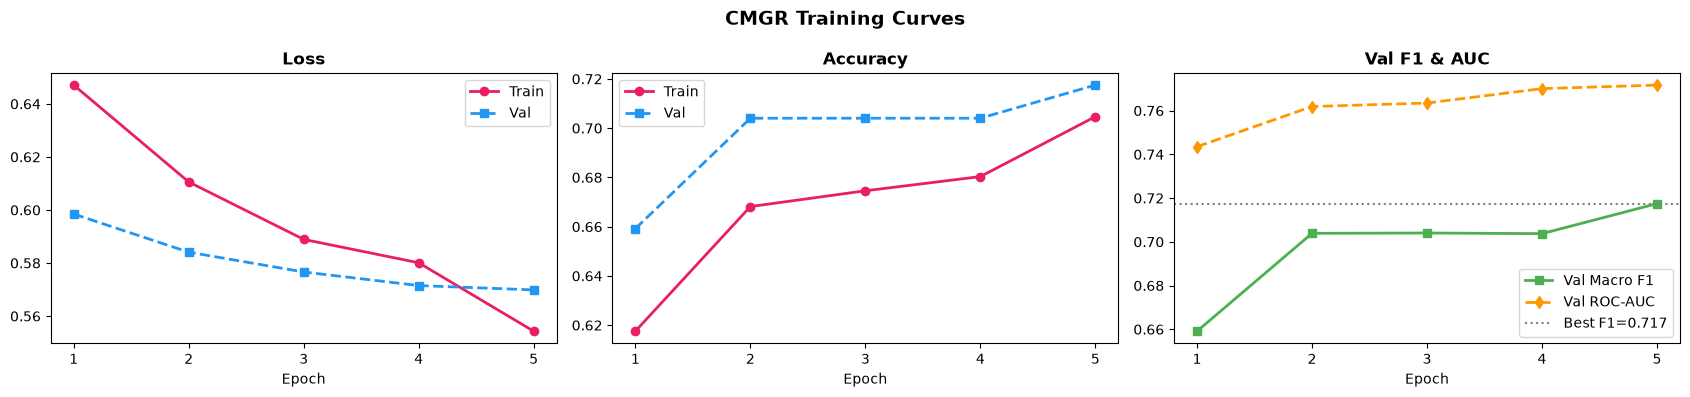

In [9]:
hist_df = pd.DataFrame(history)
epochs  = hist_df['epoch'].tolist()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Loss
axes[0].plot(epochs, hist_df['tr_loss'], 'o-', color='#E91E63', label='Train', linewidth=2)
axes[0].plot(epochs, hist_df['vl_loss'], 's--', color='#2196F3', label='Val',  linewidth=2)
axes[0].set_title('Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].legend()

# Accuracy
axes[1].plot(epochs, hist_df['tr_acc'], 'o-', color='#E91E63', label='Train', linewidth=2)
axes[1].plot(epochs, hist_df['vl_acc'], 's--', color='#2196F3', label='Val',  linewidth=2)
axes[1].set_title('Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].legend()

# Val F1 & AUC
axes[2].plot(epochs, hist_df['vl_f1'],  's-',  color='#4CAF50', label='Val Macro F1',  linewidth=2)
axes[2].plot(epochs, hist_df['vl_auc'], 'd--', color='#FF9800', label='Val ROC-AUC',   linewidth=2)
axes[2].axhline(best_val_f1, linestyle=':', color='gray', label=f'Best F1={best_val_f1:.3f}')
axes[2].set_title('Val F1 & AUC', fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].legend()

for ax in axes:
    ax.set_xticks(epochs)

plt.suptitle('CMGR Training Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('cmgr_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 10 — Test Set Evaluation

In [10]:
# Load best checkpoint
model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
model.eval()
print(f'Loaded best model from: {SAVE_PATH}\n')

_, te_acc, te_f1, te_auc, te_preds, te_labels, te_probs = eval_epoch(
    model, test_loader, criterion, device
)

print('=' * 55)
print('  CMGR — TEST SET RESULTS')
print('=' * 55)
print(f'  Accuracy  : {te_acc:.4f}')
print(f'  Macro F1  : {te_f1:.4f}')
print(f'  ROC-AUC   : {te_auc:.4f}')
print('=' * 55)
print()
print(classification_report(
    te_labels, te_preds,
    target_names=['Multi-hop (0)', 'Shortcut (1)']
))

Loaded best model from: ../../model/saved_models/cmgr_best.pt

  CMGR — TEST SET RESULTS
  Accuracy  : 0.7226
  Macro F1  : 0.7226
  ROC-AUC   : 0.8082

               precision    recall  f1-score   support

Multi-hop (0)       0.71      0.74      0.72       220
 Shortcut (1)       0.74      0.70      0.72       227

     accuracy                           0.72       447
    macro avg       0.72      0.72      0.72       447
 weighted avg       0.72      0.72      0.72       447



---
## Cell 11 — Confusion Matrix

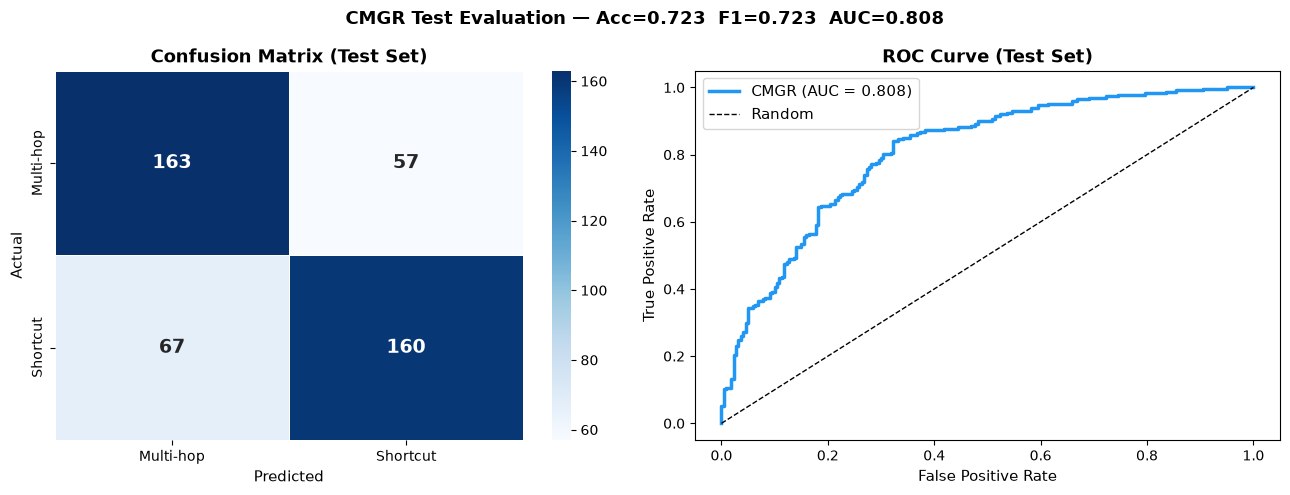

In [11]:
cm = confusion_matrix(te_labels, te_preds)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix heatmap
sns.heatmap(
    cm, ax=axes[0], annot=True, fmt='d', cmap='Blues',
    xticklabels=['Multi-hop', 'Shortcut'],
    yticklabels=['Multi-hop', 'Shortcut'],
    linewidths=0.5, annot_kws={'size': 14, 'weight': 'bold'}
)
axes[0].set_xlabel('Predicted', fontsize=11)
axes[0].set_ylabel('Actual', fontsize=11)
axes[0].set_title('Confusion Matrix (Test Set)', fontweight='bold', fontsize=13)

# ROC curve
fpr, tpr, _ = roc_curve(te_labels, te_probs)
axes[1].plot(fpr, tpr, color='#2196F3', linewidth=2.5,
             label=f'CMGR (AUC = {te_auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
axes[1].set_xlabel('False Positive Rate', fontsize=11)
axes[1].set_ylabel('True Positive Rate', fontsize=11)
axes[1].set_title('ROC Curve (Test Set)', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=11)

plt.suptitle(f'CMGR Test Evaluation — Acc={te_acc:.3f}  F1={te_f1:.3f}  AUC={te_auc:.3f}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('cmgr_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Cell 12 — Gate Interpretability (Research Paper Figure)

**Key question:** Does the gate learn to assign differential trust to the two modalities?
- `g → 1`: Router relies on the **Text Branch** (ModernBERT linguistic understanding)
- `g → 0`: Router relies on the **Tabular Branch** (retrieval signal quality)

Gate statistics (all test):
  Mean  = 0.4029
  Std   = 0.1282
  Min   = 0.1437  Max = 0.7194
  Multi-hop   : mean g = 0.4439  std = 0.1329
  Shortcut    : mean g = 0.3632  std = 0.1097


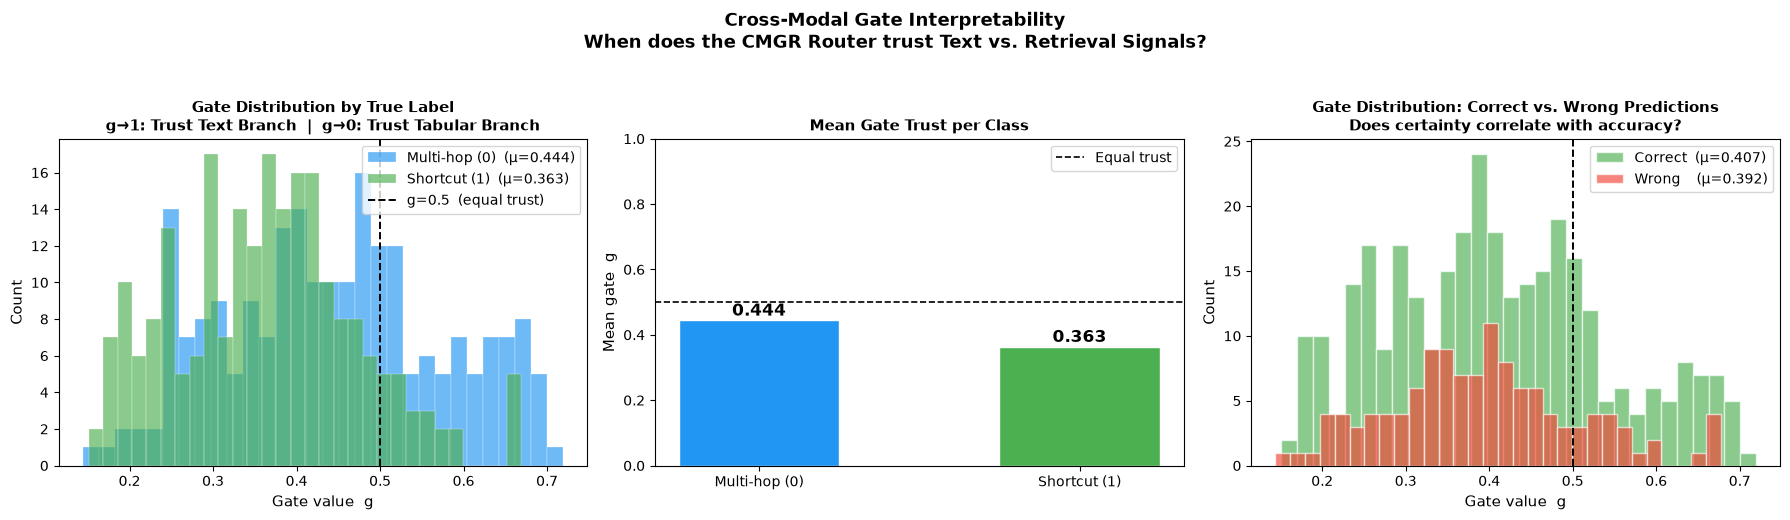

Gate interpretability figure saved → cmgr_gate_interpretability.png


In [12]:
# ── Extract scalar gate values for every test sample ─────────────────────────
model.eval()
all_gates = []

with torch.no_grad():
    for batch in test_loader:
        ids  = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        tab  = batch['tabular_features'].to(device)

        _, g = model(ids, mask, tab, return_gate=True)
        # g shape: [B, 1] in scalar mode → squeeze to [B]
        all_gates.extend(g.squeeze(1).cpu().tolist())

gate_arr    = np.array(all_gates)          # [N_test]
label_arr   = np.array(te_labels)          # [N_test]

# Sanity check
assert gate_arr.min() >= 0.0 and gate_arr.max() <= 1.0, 'Gate out of [0,1]!'
print(f'Gate statistics (all test):')
print(f'  Mean  = {gate_arr.mean():.4f}')
print(f'  Std   = {gate_arr.std():.4f}')
print(f'  Min   = {gate_arr.min():.4f}  Max = {gate_arr.max():.4f}')

for lbl, name in [(0, 'Multi-hop'), (1, 'Shortcut')]:
    g_class = gate_arr[label_arr == lbl]
    print(f'  {name:12s}: mean g = {g_class.mean():.4f}  std = {g_class.std():.4f}')

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Plot 1: Histogram by class ────────────────────────────────────────────────
colors = {0: '#2196F3', 1: '#4CAF50'}
names  = {0: 'Multi-hop (0)', 1: 'Shortcut (1)'}
for lbl in [0, 1]:
    g_class = gate_arr[label_arr == lbl]
    axes[0].hist(g_class, bins=30, alpha=0.65, color=colors[lbl],
                 label=f'{names[lbl]}  (μ={g_class.mean():.3f})', edgecolor='white', linewidth=0.3)

axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1.4, label='g=0.5  (equal trust)')
axes[0].set_xlabel('Gate value  g', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].set_title(
    'Gate Distribution by True Label\n'
    'g→1: Trust Text Branch  |  g→0: Trust Tabular Branch',
    fontweight='bold', fontsize=11
)
axes[0].legend(fontsize=10)

# ── Plot 2: Mean gate per class (bar) ─────────────────────────────────────────
means = [gate_arr[label_arr == l].mean() for l in [0, 1]]
bars  = axes[1].bar(['Multi-hop (0)', 'Shortcut (1)'], means,
                     color=[colors[0], colors[1]], edgecolor='white', width=0.5)
axes[1].set_ylim(0, 1.0)
axes[1].axhline(0.5, color='black', linestyle='--', linewidth=1.2, label='Equal trust')
axes[1].set_ylabel('Mean gate  g', fontsize=11)
axes[1].set_title('Mean Gate Trust per Class', fontweight='bold', fontsize=11)
axes[1].legend(fontsize=10)
for bar, v in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.015,
                 f'{v:.3f}', ha='center', fontsize=12, fontweight='bold')

# ── Plot 3: Gate vs. correct/wrong predictions ────────────────────────────────
pred_arr    = np.array(te_preds)
correct_idx = pred_arr == label_arr
axes[2].hist(gate_arr[correct_idx],  bins=30, alpha=0.65, color='#4CAF50',
             label=f'Correct  (μ={gate_arr[correct_idx].mean():.3f})', edgecolor='white')
axes[2].hist(gate_arr[~correct_idx], bins=30, alpha=0.65, color='#F44336',
             label=f'Wrong    (μ={gate_arr[~correct_idx].mean():.3f})', edgecolor='white')
axes[2].axvline(0.5, color='black', linestyle='--', linewidth=1.4)
axes[2].set_xlabel('Gate value  g', fontsize=11)
axes[2].set_ylabel('Count', fontsize=11)
axes[2].set_title('Gate Distribution: Correct vs. Wrong Predictions\n'
                   'Does certainty correlate with accuracy?',
                   fontweight='bold', fontsize=11)
axes[2].legend(fontsize=10)

plt.suptitle(
    'Cross-Modal Gate Interpretability\n'
    'When does the CMGR Router trust Text vs. Retrieval Signals?',
    fontsize=13, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.savefig('cmgr_gate_interpretability.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gate interpretability figure saved → cmgr_gate_interpretability.png')

---
## Cell 13 — Full Comparative Results Table

In [13]:
# Prior baseline results (from paper experiments)
prior_results = {
    'Logistic Regression (7 feat)':  {'Accuracy': 0.688, 'Macro F1': 0.686, 'ROC-AUC': 0.688, 'Input': 'Tabular'},
    'LightGBM (7 feat)':             {'Accuracy': 0.677, 'Macro F1': 0.680, 'ROC-AUC': 0.773, 'Input': 'Tabular'},
    'XGBoost Baseline (7 feat)':     {'Accuracy': 0.686, 'Macro F1': 0.685, 'ROC-AUC': 0.769, 'Input': 'Tabular'},
    'XGBoost Retrieval (11 feat)':   {'Accuracy': 0.695, 'Macro F1': 0.694, 'ROC-AUC': 0.772, 'Input': 'Tabular'},
    'XGBoost Optimized (20 feat)':   {'Accuracy': 0.722, 'Macro F1': 0.722, 'ROC-AUC': 0.793, 'Input': 'Tabular'},
    'MiniLM-L6-v2 (LoRA)':          {'Accuracy': 0.710, 'Macro F1': 0.710, 'ROC-AUC': None,   'Input': 'Text'},
    'DeBERTa-v3-base (LoRA)':       {'Accuracy': 0.722, 'Macro F1': 0.720, 'ROC-AUC': None,   'Input': 'Text'},
    'ModernBERT-base (LoRA)':        {'Accuracy': 0.722, 'Macro F1': 0.722, 'ROC-AUC': None,   'Input': 'Text'},
}

# Add CMGR result
prior_results['★ CMGR (Ours)'] = {
    'Accuracy': round(te_acc, 4),
    'Macro F1': round(te_f1, 4),
    'ROC-AUC':  round(te_auc, 4),
    'Input': 'Text + Tabular (Fusion)',
}

results_df = pd.DataFrame(prior_results).T
results_df = results_df.reset_index().rename(columns={'index': 'Model'})
results_df['Accuracy'] = results_df['Accuracy'].apply(lambda x: f'{x:.4f}' if x is not None else '—')
results_df['Macro F1'] = results_df['Macro F1'].apply(lambda x: f'{x:.4f}' if x is not None else '—')
results_df['ROC-AUC']  = results_df['ROC-AUC'].apply(lambda x:  f'{x:.4f}' if x is not None else '—')

print('\n' + '=' * 80)
print('  FULL COMPARATIVE RESULTS — MULTIHOP SHORTCUT DETECTOR')
print('=' * 80)
print(results_df.to_string(index=False))
print('=' * 80)
print(f'\n  Best prior single-modality F1 : 0.7220')
print(f'  CMGR (Ours) Macro F1         : {te_f1:.4f}')
delta = te_f1 - 0.7220
sign  = '+' if delta >= 0 else ''
print(f'  Δ vs. best baseline           : {sign}{delta:.4f} ({sign}{delta*100:.2f}%)')


  FULL COMPARATIVE RESULTS — MULTIHOP SHORTCUT DETECTOR
                       Model Accuracy Macro F1 ROC-AUC                   Input
Logistic Regression (7 feat)   0.6880   0.6860  0.6880                 Tabular
           LightGBM (7 feat)   0.6770   0.6800  0.7730                 Tabular
   XGBoost Baseline (7 feat)   0.6860   0.6850  0.7690                 Tabular
 XGBoost Retrieval (11 feat)   0.6950   0.6940  0.7720                 Tabular
 XGBoost Optimized (20 feat)   0.7220   0.7220  0.7930                 Tabular
         MiniLM-L6-v2 (LoRA)   0.7100   0.7100       —                    Text
      DeBERTa-v3-base (LoRA)   0.7220   0.7200       —                    Text
      ModernBERT-base (LoRA)   0.7220   0.7220       —                    Text
               ★ CMGR (Ours)   0.7226   0.7226  0.8082 Text + Tabular (Fusion)

  Best prior single-modality F1 : 0.7220
  CMGR (Ours) Macro F1         : 0.7226
  Δ vs. best baseline           : +0.0006 (+0.06%)


---
## Cell 14 — Save Scaler & Gate Stats for Paper

In [14]:
import pickle

# Save scaler
scaler_path = '../../model/saved_models/cmgr_scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)

# Save gate values and labels for external analysis
gate_output = {
    'gate_values': gate_arr.tolist(),
    'true_labels': label_arr.tolist(),
    'predictions': pred_arr.tolist(),
    'probs':       te_probs,
}
gate_path = '../../model/saved_models/cmgr_gate_values.json'
with open(gate_path, 'w') as f:
    json.dump(gate_output, f)

# Summary
print('Artifacts saved:')
print(f'  Model state dict    → {SAVE_PATH}')
print(f'  StandardScaler      → {scaler_path}')
print(f'  Gate values (test)  → {gate_path}')
print(f'  Training curves     → cmgr_training_curves.png')
print(f'  Evaluation plots    → cmgr_evaluation.png')
print(f'  Gate figure (paper) → cmgr_gate_interpretability.png')
print(f'\n✅ CMGR experiment complete.')

Artifacts saved:
  Model state dict    → ../../model/saved_models/cmgr_best.pt
  StandardScaler      → ../../model/saved_models/cmgr_scaler.pkl
  Gate values (test)  → ../../model/saved_models/cmgr_gate_values.json
  Training curves     → cmgr_training_curves.png
  Evaluation plots    → cmgr_evaluation.png
  Gate figure (paper) → cmgr_gate_interpretability.png

✅ CMGR experiment complete.
